# Lecture 12 — NumPy

In [1]:
import numpy as np

## The for loop

In `for ... in ndarray` constructions, multidimensional arrays are iterated only along the first index.

If it is necessary to iterate over all elements, the `flat` attribute can be used, which converts a multidimensional array into a one-dimensional one, or a nested loop can be used.

In [103]:
a = np.arange(10,16).reshape(2,-1)
print('array a')
print(a, end='\n\n')

array a
[[10 11 12]
 [13 14 15]]



In [104]:
for i in a:
    print('row',i)
print()

row [10 11 12]
row [13 14 15]



In [105]:
for i in a.flat:
    print('element',i)

element 10
element 11
element 12
element 13
element 14
element 15


In [3]:
for i in a:
    for j in i:
        print('element',j)


element 10
element 11
element 12
element 13
element 14
element 15


## The NumPy nditer object

`nditer` is a multidimensional iterator object that allows iterating over all elements of an array.

In [106]:
a = np.arange(10,16).reshape(2,-1)
print('array a')
print(a, end='\n\n')

array a
[[10 11 12]
 [13 14 15]]



In [107]:
print('nditer default order (C)')
for i in np.nditer(a):
    print(i, end=' ')
print()

nditer default order (C)
10 11 12 13 14 15 


In [5]:
print('nditer order F')
for i in np.nditer(a,order='F'):
    print(i, end=' ')

nditer order F
10 13 11 14 12 15 

The `nditer` array elements are read-only. If an attempt is made to modify the element values, an error message is output.

In [6]:
a = np.arange(10,16).reshape(2,-1)
print(a)

for i in np.nditer(a):
    i[...] = i**2


[[10 11 12]
 [13 14 15]]


<class 'ValueError'>: assignment destination is read-only

The `op_flags` parameter allows modifying `nditer` array values:

In [110]:
a = np.arange(10,16).reshape(2,-1)
print('array a before')
print(a, end='\n\n')

for i in np.nditer(a,op_flags=['readwrite']):
    i[...] = i + 10

print('array a after')
print(a)


array a before
[[10 11 12]
 [13 14 15]]

array a after
[[20 21 22]
 [23 24 25]]


## Mathematical operations

Arrays allow performing operations on data without using a `for` loop, this is called vectorization.

NumPy arrays can be ordinary operands of mathematical expressions:

In [8]:
a = np.arange(1,10).reshape(3,3)
print('array a')
print(a, end='\n\n')

array a
[[1 2 3]
 [4 5 6]
 [7 8 9]]



In [9]:
print('a + 5')
print(a+5, end='\n\n')
print('a % 2')
print(a%2, end='\n\n')
print('10 / a')
print(10/a, end='\n\n')

a + 5
[[ 6  7  8]
 [ 9 10 11]
 [12 13 14]]

a % 2
[[1 0 1]
 [0 1 0]
 [1 0 1]]

10 / a
[[10.          5.          3.33333333]
 [ 2.5         2.          1.66666667]
 [ 1.42857143  1.25        1.11111111]]



Operations are performed element-wise no matter which side the array is on — `a**3` raises every element to the 3rd power, and unary `-a` negates every element:

In [10]:
print('a ** 3')
print(a**3, end='\n\n')
print('-a')
print(-a)

a ** 3
[[  1   8  27]
 [ 64 125 216]
 [343 512 729]]

-a
[[-1 -2 -3]
 [-4 -5 -6]
 [-7 -8 -9]]


Operations such as `+=`, `-=`, `*=`, `/=`, etc., can also be applied to arrays and are also performed element-wise. They do not create a new array, but modify the old one:

In [11]:
a = np.arange(1,10).reshape(3,3)
a *= 10
print(a)


[[10 20 30]
 [40 50 60]
 [70 80 90]]


Operations must not change the type of the array:

In [12]:
a = np.arange(1,10).reshape(3,3)
a /= 2 # changes the type of the array elements
print(a)


<class 'numpy._core._exceptions._UFuncOutputCastingError'>: Cannot cast ufunc 'divide' output from dtype('float64') to dtype('int32') with casting rule 'same_kind'

In [14]:
a = np.arange(1,10).reshape(3,3)
a %= 2 # the type of the array elements does not change
print(a)


[[1 0 1]
 [0 1 0]
 [1 0 1]]


Operations on arrays of the same shape are also performed element-wise.

In [15]:
a = np.arange(11,16)
b = np.linspace(0, 5, 5)
print('array a')
print(a)
print('array b')
print(b)

array a
[11 12 13 14 15]
array b
[0.   1.25 2.5  3.75 5.  ]


In [16]:
print('a*2 + b')
print(a*2+b)


a*2 + b
[22.   25.25 28.5  31.75 35.  ]


In [17]:
a = np.arange(11,16)
b = np.linspace(0, 5, 5)
print('array a')
print(a)
print('array b')
print(b)



array a
[11 12 13 14 15]
array b
[0.   1.25 2.5  3.75 5.  ]


In [18]:
a *= b # the float64 type cannot be converted to the int64 type
print('a *= b')
print(a)

<class 'numpy._core._exceptions._UFuncOutputCastingError'>: Cannot cast ufunc 'multiply' output from dtype('float64') to dtype('int32') with casting rule 'same_kind'

In [19]:
a = np.arange(11,16)
b = np.linspace(0, 5, 5)
print('array a')
print(a)
print('array b')
print(b)

array a
[11 12 13 14 15]
array b
[0.   1.25 2.5  3.75 5.  ]


In [20]:
b *= a # conversion of int64 type to float64 type is allowed
print('b *= a')
print(b)


b *= a
[ 0.  15.  32.5 52.5 75. ]


In [111]:
a = np.arange(11,16)
print('a.dtype')
print(a.dtype)

a.dtype
int32


In [112]:
b = np.linspace(0, 5, 5)
print('b.dtype')
print(b.dtype)

b.dtype
float64


In [22]:
c = a + b
print('c.dtype (a + b)')
print(c.dtype)

c.dtype (a + b)
float64


## inf, -inf, nan values

The values `inf` and `-inf` are returned when the result of a mathematical operation is plus infinity (∞) or minus infinity (-∞).

The value `nan` is returned when it is not possible to determine the result of a calculation:

In [23]:
a = np.array([0,1,2],dtype=float)
b = np.array([1,2,3],dtype=float)

b /= a
print('b /= a')
print(b)

b /= a
[inf 2.  1.5]


Since `b` now contains `inf` (from dividing by zero), applying `cos()` to it produces `nan` where the result is undefined:

In [24]:
c = (np.cos(b))
print('cos(b)')
print(c)

cos(b)
[        nan -0.41614684  0.0707372 ]


`log(0)` similarly produces `-inf` rather than raising an error:

In [25]:
d = np.array([np.log(0)])
print('log(0)')
print(d)

log(0)
[-inf]


NumPy may warn that it detected an `inf` or `nan` value, but no error occurred.

### The functions isinf(), isneginf(), isposinf(), isnan()

`isinf(a [, out])`

The function checks whether an array element is plus or minus infinity. Returns the result as an array of boolean values.

Parameters:
- `a` – array;
- `out` – result array.

`isneginf(a [, out])` – the function checks whether an array element is minus infinity.

`isposinf(a [, out])` – the function checks whether an array element is plus infinity.

`isnan(a [, out])` – the function checks whether an array element is `nan`.

The file `file.txt` used in the example below contains:
```
3 inf 2 nan
2 4 nan 9
inf 9 5 6
7 8 -inf -inf
```

In [113]:
a = np.loadtxt('file.txt')
print('array a')
print(a, end='\n\n')
b = np.zeros((4,4))

array a
[[11. 21. 31. 41.]
 [10. 20. 30. 40.]
 [23. 24. 25. 26.]
 [ 1.  2.  3.  4.]]



In [114]:
np.isinf(a, out=b)
print('isinf(a) written into b')
print(b, end='\n\n')

isinf(a) written into b
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]



In [115]:
print('isinf(a)')
print(np.isinf(a), end='\n\n')

isinf(a)
[[False False False False]
 [False False False False]
 [False False False False]
 [False False False False]]



Boolean arrays like the ones returned above can be used directly as index masks to replace the special values in place:

In [27]:
# indexing with bool type arrays
a[np.isneginf(a)] = -1
a[np.isposinf(a)] = 1
a[np.isnan(a)] = 0
print('a after replacing -inf/inf/nan')
print(a)

a after replacing -inf/inf/nan
[[11. 21. 31. 41.]
 [10. 20. 30. 40.]
 [23. 24. 25. 26.]
 [ 1.  2.  3.  4.]]


## Broadcasting

The term broadcasting refers to NumPy's ability to process arrays of different shapes when performing arithmetic operations. The smaller array is broadcast to the size of the larger array, so that they have compatible shapes.

Two arrays are considered compatible if their dimensions are equal or one of the dimensions equals 1.

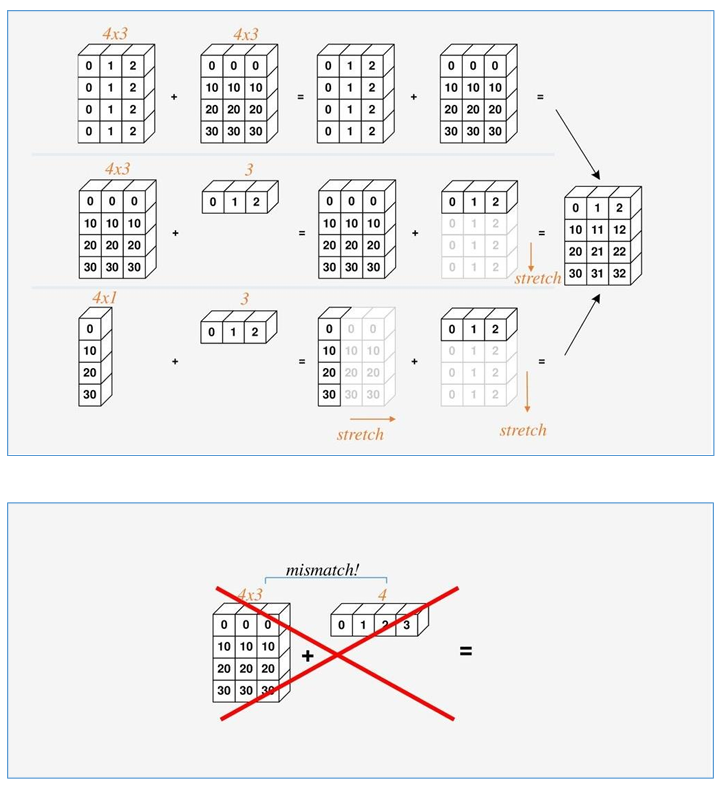

In [28]:
a = np.arange(11,20).reshape(3,-1)
b = np.array([10,10,10])
c = np.array([[5],[4],[3]])
print('array a')
print(a, end='\n\n')
print('array b')
print(b, end='\n\n')
print('array c')
print(c, end='\n\n')

array a
[[11 12 13]
 [14 15 16]
 [17 18 19]]

array b
[10 10 10]

array c
[[5]
 [4]
 [3]]



In [29]:
a -= c
print('a -= c')
print(a, end='\n\n')

a -= c
[[ 6  7  8]
 [10 11 12]
 [14 15 16]]



Here `c` has shape (3,1) and `a` has shape (3,3) — `c` is broadcast across each column. The same idea applies to division, and to multiplying the 1-D array `b` by the column array `c`:

In [30]:
print('a/c')
print(a/c, end='\n\n')
print('b*c')
print(b*c)

a/c
[[1.2        1.4        1.6       ]
 [2.5        2.75       3.        ]
 [4.66666667 5.         5.33333333]]

b*c
[[50 50 50]
 [40 40 40]
 [30 30 30]]


In [31]:
a = np.arange(4).reshape(2,-1)
b = np.array([10,10,10])

print('array a')
print(a)
print('array b')
print(b)


array a
[[0 1]
 [2 3]]
array b
[10 10 10]


In [32]:
print('a / c (incompatible shapes -> error)')
print(a/c)

a / c (incompatible shapes -> error)


<class 'ValueError'>: operands could not be broadcast together with shapes (2,2) (3,1) 

In [33]:
a = np.arange(16).reshape(4,-1)
b = np.arange(8).reshape(4,-1)

print('array a')
print(a)
print('array b')
print(b)


array a
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]
 [12 13 14 15]]
array b
[[0 1]
 [2 3]
 [4 5]
 [6 7]]


In [34]:
print('a * b')
print(a*b)

a * b


<class 'ValueError'>: operands could not be broadcast together with shapes (4,4) (4,2) 

## The ix_() function

```
ix_(*args)
```

The function takes one-dimensional arrays and returns a set (tuple) of matching (broadcast-compatible) multidimensional arrays.

In [35]:
a = np.array([1,2,3,4,5])
b = np.array([5,6,7,8,9,10,11])

ax,bx = np.ix_(a,b) # tuple unpacking
print('ax')
print(ax)
print('ax.shape')
print(ax.shape, end='\n\n')

ax
[[1]
 [2]
 [3]
 [4]
 [5]]
ax.shape
(5, 1)



In [36]:
print('bx')
print(bx)
print('bx.shape')
print(bx.shape, end='\n\n')

bx
[[ 5  6  7  8  9 10 11]]
bx.shape
(1, 7)



`ax` and `bx` now have broadcast-compatible shapes ((5,1) and (1,7)), so an operation between them produces a full 2-D result — combining every element of `a` with every element of `b`:

In [37]:
c = bx**ax
print('c = bx ** ax')
print(c)
print('c.shape')
print(c.shape)

c = bx ** ax
[[     5      6      7      8      9     10     11]
 [    25     36     49     64     81    100    121]
 [   125    216    343    512    729   1000   1331]
 [   625   1296   2401   4096   6561  10000  14641]
 [  3125   7776  16807  32768  59049 100000 161051]]
c.shape
(5, 7)


In [38]:
a = np.array([-1,1])
b = np.array([2,3,4])
c = np.array([5,6,7,8,9])

ixarr = np.ix_(a,b,c)
print('ixarr')
print(ixarr, end='\n\n')

ixarr
(array([[[-1]],

       [[ 1]]]), array([[[2],
        [3],
        [4]]]), array([[[5, 6, 7, 8, 9]]]))



In [39]:
print('ixarr[0].shape =',ixarr[0].shape, end='\n\n')
print('ixarr[1].shape =',ixarr[1].shape, end='\n\n')
print('ixarr[2].shape =',ixarr[2].shape, end='\n\n')

ixarr[0].shape = (2, 1, 1)

ixarr[1].shape = (1, 3, 1)

ixarr[2].shape = (1, 1, 5)



With three broadcast-compatible arrays, the same idea extends to three dimensions — combining every element of `a`, `b`, and `c`:

In [40]:
d = ixarr[2] * ixarr[0] + ixarr[1]
print('d = ixarr[2] * ixarr[0] + ixarr[1]')
print(d, end='\n\n')

print('d.shape =',d.shape)

d = ixarr[2] * ixarr[0] + ixarr[1]
[[[-3 -4 -5 -6 -7]
  [-2 -3 -4 -5 -6]
  [-1 -2 -3 -4 -5]]

 [[ 7  8  9 10 11]
  [ 8  9 10 11 12]
  [ 9 10 11 12 13]]]

d.shape = (2, 3, 5)


## Universal functions (ufunc)

NumPy universal functions are objects belonging to the `numpy.ufunc` class. They perform element-wise operations on the data of an `ndarray` object.

In [41]:
print(type(np.cos))


<class 'numpy.ufunc'>


These functions include standard trigonometric functions, arithmetic operation functions, complex number handling, statistical functions, etc.

### Unary universal functions (Unary ufuncs)

| Function | Description |
|---|---|
| abs | Compute the absolute value of an element |
| sqrt | Compute the square root of each element. Equivalent to `arr ** 0.5` |
| square | Compute the square of each element. Equivalent to `arr ** 2` |
| exp | Compute the exponential function e^x of each element |
| log, log10, log2, log1p | Natural logarithm (base e), log base 10, log base 2, log(1 + x) |
| sign | Returns the sign of each element: 1 (positive), 0 (zero), or -1 (negative) |
| ceil | Rounds a number up to the nearest integer |
| floor | Rounds a number down to the nearest integer |
| rint | Rounds elements to the nearest integer, preserving dtype |
| cos, cosh, sin, sinh, tan, tanh | Regular and hyperbolic trigonometric functions |
| arccos, arccosh, arcsin, arcsinh, arctan, arctanh | Inverse trigonometric functions |
| logical_not | Logical NOT. Equivalent to `-arr` |
| deg2rad | Converts degrees to radians |
| rad2deg | Converts radians to degrees |
| unique | Finds the unique elements of an array |
| cumprod | Returns the cumulative product of elements along a given axis |
| cumsum | Returns the cumulative sum of elements along a given axis |
| diff | Computes the n-th discrete difference along a given axis |

In trigonometric functions, angle values must be expressed in radians.

π – `np.pi`

In [42]:
x = np.arange(0, 100, 15)
print('array x (degrees)')
print(x, end='\n\n')


array x (degrees)
[ 0 15 30 45 60 75 90]



In [43]:
xtan = np.tan(np.deg2rad(x))
print('tan(x)')
print(xtan, end='\n\n')

tan(x)
[0.00000000e+00 2.67949192e-01 5.77350269e-01 1.00000000e+00
 1.73205081e+00 3.73205081e+00 1.63312394e+16]



In [44]:
xarctan = np.rad2deg(np.arctan(xtan))
print('arctan(xtan) back in degrees')
print(xarctan, end='\n\n')

arctan(xtan) back in degrees
[ 0. 15. 30. 45. 60. 75. 90.]



`unique()` is another common unary function — it returns the sorted, distinct values found in an array:

In [116]:
a = np.random.randint(10,size=(3,3))
print('array a')
print(a, end='\n\n')

array a
[[8 5 8]
 [6 4 8]
 [1 9 6]]



In [117]:
print('unique(a)')
print(np.unique(a))

unique(a)
[1 4 5 6 8 9]


In [118]:
a = np.arange(1,10).reshape(3,3)
print('array a')
print(a, end='\n\n')

array a
[[1 2 3]
 [4 5 6]
 [7 8 9]]



In [119]:
print('cumsum(a)') # cumulative sum of all elements
print(np.cumsum(a), end='\n\n')

cumsum(a)
[ 1  3  6 10 15 21 28 36 45]



Passing `axis` computes the cumulative sum along rows or columns instead of flattening the array first:

In [120]:
print('cumsum(a, axis=0)') # cumulative sum of columns
print(np.cumsum(a, axis=0), end='\n\n')

cumsum(a, axis=0)
[[ 1  2  3]
 [ 5  7  9]
 [12 15 18]]



In [121]:
print('cumsum(a, axis=1)') # cumulative sum of rows
print(np.cumsum(a, axis=1))

cumsum(a, axis=1)
[[ 1  3  6]
 [ 4  9 15]
 [ 7 15 24]]


In [122]:
a = np.random.randint(10,size=(4,4))
print('array a')
print(a, end='\n\n')

array a
[[5 1 8 6]
 [6 3 4 1]
 [6 4 6 5]
 [1 0 6 9]]



In [123]:
print('diff(a, axis=1)') # difference of neighboring row elements
print(np.diff(a,axis=1))

diff(a, axis=1)
[[-4  7 -2]
 [-3  1 -3]
 [-2  2 -1]
 [-1  6  3]]


In [124]:
a = np.array([10, 20, np.nan, np.nan, 50])
print('array a')
print(a)

array a
[10. 20. nan nan 50.]


In [125]:
bool_a = np.logical_not(np.isnan(a))
print('bool_a')
print(bool_a)

bool_a
[ True  True False False  True]


In [50]:
a = a[bool_a] # removing nan values
print('a after removing nan')
print(a)
# or a = a[np.logical_not(np.isnan(a))]

a after removing nan
[10. 20. 50.]


### Binary universal functions (Binary ufuncs)

| Function | Description |
|---|---|
| add | Adds the elements of the specified arrays |
| subtract | Subtracts the elements of the second array from the first array |
| multiply | Multiplies array elements |
| divide, floor_divide | Divides the elements of the first array by the elements of the second array. floor_divide also rounds down to the nearest integer |
| power | Raises the elements of the first array to the powers indicated in the second array |
| maximum, fmax | Selects the largest element. fmax ignores NaN |
| minimum, fmin | Selects the smallest element. fmin ignores NaN |
| mod | Returns the remainder of division |
| copysign | Copies the sign of the second array's values to the first array's values |
| greater, greater_equal, less, less_equal, equal, not_equal | Equivalent to >, >=, <, <=, ==, != |
| logical_and, logical_or, logical_xor | Logical AND, logical OR, logical XOR. Equivalent to &, \|, ^ |
| in1d | Returns an array of the same length as arr1, with values True if the element of array arr1 is in arr2, False otherwise |
| intersect1d | Returns the sorted, unique values present in both arrays |
| setdiff1d | Returns the unique values of arr1 that are not in arr2 |
| setxor1d | Returns the sorted, unique values that are only in one (not both) of the input arrays |
| union1d | Returns the unique, sorted array of values, with values present in either array |


In [51]:
a = np.array([True, False, True, False])
b = np.array([True, True, False, False])
print('array a')
print(a)
print('array b')
print(b, end='\n\n')

array a
[ True False  True False]
array b
[ True  True False False]



`logical_and`, `logical_or`, and `logical_xor` combine two boolean arrays element-wise:

In [52]:
print('logical_and(a,b)')
print(np.logical_and(a,b))
print('logical_or(a,b)')
print(np.logical_or(a,b))
print('logical_xor(a,b)')
print(np.logical_xor(a,b))

logical_and(a,b)
[ True False False False]
logical_or(a,b)
[ True  True  True False]
logical_xor(a,b)
[False  True  True False]


In [53]:
c = np.random.randint(20,size=(3,3))
d = np.random.randint(20,size=(3,3))

print('array c')
print(c, end='\n\n')
print('array d')
print(d, end='\n\n')

array c
[[ 4  5 18]
 [19  4 14]
 [ 0 18 16]]

array d
[[ 5  7 11]
 [12  7  2]
 [13 11  6]]



`union1d()` returns the sorted set of unique values that appear in either array; `maximum()` instead keeps the arrays' shape and takes the element-wise larger value:

In [126]:
# np.in1d() was removed in favor of np.isin(), which provides the same functionality with a clearer name
# print(np.in1d(c,d))
print('union1d(c,d)')
print(np.union1d(c,d), end='\n\n')

union1d(c,d)
[ 1  2  3  4 11 12 13 14]



In [127]:
print('maximum(c,d)')
print(np.maximum(c,d))

maximum(c,d)
[[11 12]
 [13 14]]


In [55]:
a = np.random.randint(10,size=(4,4))
print('array a')
print(a, end='\n\n')

b = np.random.randint(10,size=(3,3))
print('array b')
print(b, end='\n\n')




array a
[[4 7 1 1]
 [9 4 4 2]
 [8 3 4 2]
 [9 9 9 2]]

array b
[[5 5 8]
 [4 2 7]
 [5 1 9]]



In [56]:
print('setxor1d(a,b)')
print(np.setxor1d(a,b))

setxor1d(a,b)
[3 5]


## Aggregation functions

When dealing with a large amount of data, it is often first necessary to compute summary statistics for the relevant data. Perhaps the most common summary statistics are the mean and standard deviation, which allow summarizing the "typical" values of a dataset, but other summary indicators (sum, product, median, min and max, etc.) are also useful.

| Function | Description |
|---|---|
| sum | Computes the sum of elements |
| prod | Computes the product of elements |
| mean | Computes the mean of elements |
| std | Computes the standard deviation |
| var | Computes the variance |
| min | Finds the smallest value |
| max | Finds the largest value |
| argmin | Finds the index of the smallest value |
| argmax | Finds the index of the largest value |
| median | Computes the median of elements |
| any | Determines whether there are elements whose value is True |
| all | Determines whether all elements' values are True |

By default, these operations are applied to the entire array, but if an axis is specified as a parameter, the calculations will be performed in the direction of that axis.

In [57]:
a = np.linspace(-12,18,16).reshape(4,4)
print('array a')
print(a, end='\n\n')


array a
[[-12. -10.  -8.  -6.]
 [ -4.  -2.   0.   2.]
 [  4.   6.   8.  10.]
 [ 12.  14.  16.  18.]]



In [58]:
print('sum')
print(np.sum(a))
print(np.sum(a,axis=1), end='\n\n') # result output as a row

sum
48.0
[-36.  -4.  28.  60.]



In [59]:
print('all')
print(np.all(a))
print(np.all(a,axis=1), end='\n\n') # result output as a row

all
False
[ True False  True  True]



Just like `sum()` and `all()`, most aggregation functions accept an `axis` argument and return one result per row (or column) instead of a single overall value:

In [60]:
print('mean')
print(np.mean(a))
print(np.mean(a,axis=0), end='\n\n')


mean
3.0
[0. 2. 4. 6.]



In [61]:
print('min')
print(np.min(a))
print(np.min(a,axis=0), end='\n\n')

min
-12.0
[-12. -10.  -8.  -6.]



`argmax()` (and its counterpart `argmin()`) return the *index* of the extreme value rather than the value itself — here, the index into the flattened array:

In [62]:
print('argmax')
print(np.argmax(a))

argmax
15


## The vectorize() function

```
vectorize(pyfunc)
```

The function converts a Python function into a universal function, which allows creating a user's own universal function.

In [130]:
a = np.random.randint(20,size=(4,4))
b = np.arange(10,14)
c = np.arange(1,17).reshape(4,4)

def f(x,y):
    if x < y:
        return x*y
    elif x == y:
        return -1
    return x//y

fv = np.vectorize(f)

print('array a')
print(a, end='\n\n')
print('array b')
print(b, end='\n\n')
print('array c')
print(c, end='\n\n')

array a
[[ 4  7  5  7]
 [ 4  0  9 10]
 [ 5  3  4 11]
 [15  9 17 12]]

array b
[10 11 12 13]

array c
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]
 [13 14 15 16]]



In [131]:
print('fv(a, 15)')
print(fv(a,15), end='\n\n')

fv(a, 15)
[[ 60 105  75 105]
 [ 60   0 135 150]
 [ 75  45  60 165]
 [ -1 135   1 180]]



`fv` also works with two arrays instead of an array and a scalar — the second argument broadcasts just like an ordinary NumPy operation would:

In [132]:
print('fv(a, b)')
print(fv(a,b), end='\n\n')

fv(a, b)
[[ 40  77  60  91]
 [ 40   0 108 130]
 [ 50  33  48 143]
 [  1  99   1 156]]



In [133]:
print('fv(a, c)')
print(fv(a,c))

fv(a, c)
[[  4   3   1   1]
 [ 20   0   1   1]
 [ 45  30  44 132]
 [  1 126   1 192]]


## The where() function

```
where(condition, x, y)
```

The `where()` function is a vectorized version of the ternary expression `x if condition else y`.

In [66]:
a = np.linspace(-10,10,6)
print('array a')
print(a, end='\n\n')


array a
[-10.  -6.  -2.   2.   6.  10.]



In [67]:
a = np.where(a<=0, a, a*10)
print('a after where(a<=0, a, a*10)')
print(a, end='\n\n')

a after where(a<=0, a, a*10)
[-10.  -6.  -2.  20.  60. 100.]



`where()` also supports two arrays as its `x` and `y` arguments (instead of scalars), selecting element-wise from `a` or `b` according to the boolean `cond` array:

In [68]:
b = np.arange(6)
print('array b')
print(b, end='\n\n')


array b
[0 1 2 3 4 5]



In [69]:
cond = np.array([True,False,True,False,True,False])

c = np.where(cond,a,b)
print('c = where(cond, a, b)')
print(c)

c = where(cond, a, b)
[-10.   1.  -2.   3.  60.   5.]


In [70]:
a = np.arange(16).reshape(2,-1)
print('array a')
print(a, end='\n\n')


array a
[[ 0  1  2  3  4  5  6  7]
 [ 8  9 10 11 12 13 14 15]]



In [71]:
print('where((a>=2) & (a<7), -a, a%2)')
print(np.where((a>=2) & (a<7),-a,a%2))

where((a>=2) & (a<7), -a, a%2)
[[ 0  1 -2 -3 -4 -5 -6  1]
 [ 0  1  0  1  0  1  0  1]]


In [72]:
a = np.random.randint(10,17,(3,3))
b = np.arange(10,13)
print('array a')
print(a, end='\n\n')
print('array b')
print(b, end='\n\n')



array a
[[13 14 10]
 [13 15 12]
 [10 10 16]]

array b
[10 11 12]



In [73]:
c = np.where(a>b,a,0) # supports broadcasting
print('c = where(a>b, a, 0)')
print(c)

c = where(a>b, a, 0)
[[13 14  0]
 [13 15  0]
 [ 0  0 16]]


## Linear algebra

| Function | Description |
|---|---|
| dot | Matrix product |
| vdot | Scalar (dot) product of vectors |

The NumPy package includes the `numpy.linalg` module, which provides all the functions needed for linear algebra. Some important functions of this module are described in the table below.

| Function | Description |
|---|---|
| det | Computes the determinant of a matrix |
| eig | Computes the eigenvalues and eigenvectors of a square matrix |
| inv | Computes the inverse of a matrix |
| matrix_power | Raises a square matrix to the power n |
| matrix_rank | Returns the rank of a matrix |
| solve | Solves the system of linear equations Ax = b |

### dot – matrix product

The matrix sizes must either be equal, and the matrices themselves square, or they must be compatible, i.e. if the dimensions of matrix A are [m, k], the dimensions of matrix B must be [k, n]:

```
C[m,n] = A[m,k] × B[k,n]
```

In [74]:
#t wo matrices
a = np.arange(1,7).reshape(2,3)
b = np.arange(4,10).reshape(3,2)
print('matrix a')
print(a, end='\n\n')
print('matrix b')
print(b, end='\n\n')


matrix a
[[1 2 3]
 [4 5 6]]

matrix b
[[4 5]
 [6 7]
 [8 9]]



In [75]:
print('dot(a,b)')
print(np.dot(a,b))

dot(a,b)
[[ 40  46]
 [ 94 109]]


In [76]:
# row-vector and matrix
a = np.array([1,2,3])
b = np.arange(4,10).reshape(3,2)
print('vector a')
print(a, end='\n\n')
print('matrix b')
print(b, end='\n\n')


vector a
[1 2 3]

matrix b
[[4 5]
 [6 7]
 [8 9]]



In [77]:
print('dot(a,b)')
print(np.dot(a,b))

dot(a,b)
[40 46]


In [78]:
# matrix and column-vector
a = np.array([4,5]).reshape(2,1)
b = np.arange(4,10).reshape(3,2)
print('column-vector a')
print(a, end='\n\n')
print('matrix b')
print(b, end='\n\n')



column-vector a
[[4]
 [5]]

matrix b
[[4 5]
 [6 7]
 [8 9]]



In [79]:
print('dot(b,a)')
print(np.dot(b,a)) # dot(b,a)

dot(b,a)
[[41]
 [59]
 [77]]


### vdot – scalar (dot) product of vectors

This function returns the scalar (dot) product of two vectors. If the argument is a multidimensional array, it is converted into a one-dimensional one.

In [80]:
a = np.array([1,2,3,4])
b = np.array([11,12,13,14])
print('vector a')
print(a, end='\n\n')
print('vector b')
print(b, end='\n\n')

vector a
[1 2 3 4]

vector b
[11 12 13 14]



In [81]:
print('vdot(a,b)')
print(np.vdot(a,b), end='\n\n')

vdot(a,b)
130



If the arguments are multidimensional, `vdot()` flattens them into 1-D vectors first, then computes the same scalar product:

In [82]:
c = np.array([[1,2],[3,4]])
d = np.array([[11,12],[13,14]])
print('matrix c')
print(c, end='\n\n')
print('matrix d')
print(d, end='\n\n')

matrix c
[[1 2]
 [3 4]]

matrix d
[[11 12]
 [13 14]]



In [83]:
print('vdot(c,d)')
print(np.vdot(c,d))

vdot(c,d)
130


### linalg.matrix_power – raising a matrix to a power

In [84]:
a = np.arange(1,10).reshape(3,3)
print('array a')
print(a, end='\n\n')

print('dot(a,a)')
print(np.dot(a,a), end='\n\n')

array a
[[1 2 3]
 [4 5 6]
 [7 8 9]]

dot(a,a)
[[ 30  36  42]
 [ 66  81  96]
 [102 126 150]]



In [85]:
print('matrix_power(a,2)')
print(np.linalg.matrix_power(a,2), end='\n\n')

matrix_power(a,2)
[[ 30  36  42]
 [ 66  81  96]
 [102 126 150]]



`matrix_power(a, n)` is a shorthand for multiplying a square matrix by itself `n` times; raising it to the 0th power returns the identity matrix:

In [86]:
print('matrix_power(a,5)')
print(np.linalg.matrix_power(a,5), end='\n\n')


matrix_power(a,5)
[[121824 149688 177552]
 [275886 338985 402084]
 [429948 528282 626616]]



In [87]:
print('matrix_power(a,0)')
print(np.linalg.matrix_power(a,0))

matrix_power(a,0)
[[1 0 0]
 [0 1 0]
 [0 0 1]]


### linalg.det – computing the determinant

In [88]:
a = np.array([[2,3],[4,5]])
print('matrix a')
print(a, end='\n\n')


matrix a
[[2 3]
 [4 5]]



In [89]:
print('det(a)') # 2*5-3*4
print(np.linalg.det(a), end='\n\n')

det(a)
-2.0



Floating-point determinants can carry tiny rounding errors; `round()` is often used to clean up the result for a matrix with integer entries:

In [90]:
b = np.array([[1,3],[4,3]])
print('matrix b')
print(b, end='\n\n')
print('det(b)') # 1*3-3*4
print(np.linalg.det(b), end='\n\n')

matrix b
[[1 3]
 [4 3]]

det(b)
-8.999999999999998



In [91]:
print('round(det(b))') # round()
print(round(np.linalg.det(b)))

round(det(b))
-9


### a.T – matrix transpose

In [92]:
a = np.array([[10,20],[1,2]])
print('matrix a')
print(a, end='\n\n')


matrix a
[[10 20]
 [ 1  2]]



In [93]:
print('a.T')
print(a.T, end='\n\n')

a.T
[[10  1]
 [20  2]]



Transpose works the same way on non-square matrices — rows become columns:

In [94]:
b = np.array([[1,2,3],[4,5,6]])
print('matrix b')
print(b, end='\n\n')


matrix b
[[1 2 3]
 [4 5 6]]



In [95]:
print('b.T')
print(b.T)

b.T
[[1 4]
 [2 5]
 [3 6]]


### linalg.inv – computing the inverse matrix (A⁻¹)

In [96]:
a = np.random.randint(1,10,(2,2))
print('matrix a')
print(a, end='\n\n')

matrix a
[[4 4]
 [6 9]]



In [97]:
ainv = np.linalg.inv(a)
print('inverse of a')
print(ainv, end='\n\n')

inverse of a
[[ 0.75       -0.33333333]
 [-0.5         0.33333333]]



In [98]:
print('a . a_inv (should be close to identity)')
print(np.dot(a,ainv))

a . a_inv (should be close to identity)
[[1. 0.]
 [0. 1.]]


### linalg.solve – solving a system of linear equations

```
x1 - 3x2 + 2x3 = -8
5x1 + 2x2 - x3 = 33
2x1 + 3x3 = 4
```

In [99]:
a = np.array([[1,-3,2],[5,2,-1],[2,0,3]])
print('matrix a')
print(a, end='\n\n')

b = np.array([-8,33,4])
print('vector b')
print(b, end='\n\n')

matrix a
[[ 1 -3  2]
 [ 5  2 -1]
 [ 2  0  3]]

vector b
[-8 33  4]



In [100]:
print('solution x (a @ x = b)')
print(np.linalg.solve(a,b))


solution x (a @ x = b)
[ 5.  3. -2.]


## Matrix equations

```
AX = B          XA = B
X = A⁻¹B        X = BA⁻¹
```

```
( -4   1   3 )         ( -7  21 -18 )
( -2  -1  -1 ) X   =   (  9   1  -6 )
(  4  -2   5 )         ( -4  21  20 )
```

In [101]:
# Matrix equation AX = B
A = np.array([[-4,1,3],[-2,-1,-1],[4,-2,5]])
B = np.array([[-7,21,-18],[9,1,-6],[-4,21,20]])
print('matrix A')
print(A, end='\n\n')
print('matrix B')
print(B, end='\n\n')


matrix A
[[-4  1  3]
 [-2 -1 -1]
 [ 4 -2  5]]

matrix B
[[ -7  21 -18]
 [  9   1  -6]
 [ -4  21  20]]



In [102]:
X = np.linalg.solve(A,B)
print('solution X')
print(X, end='\n\n')

solution X
[[-1. -2.  4.]
 [-5. -2. -2.]
 [-2.  5.  0.]]

